# cleaning.ipynb

Cleaning, preprocessing and exploration of Smash Ultimate data.

**To refresh with new data:** run step 04 (`python src/04_build_dataset.py`), then **Kernel → Restart & Run All**.
Nothing below needs editing; all cleaning rules live in `src/clean.py`, and every table and
figure is rebuilt from `data/processed/`. Figures are saved to `outputs/figures/`, tables to `data/clean/eda/`.

In [1]:
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# make src/ importable and pick up edits to clean.py without restarting
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import clean
importlib.reload(clean)

# ── settings ──
MIN_GAMES = 100        # "sufficient observations" cutoff per matchup
N_BOOT = 1000          # cluster-bootstrap resamples (by set) for matchup CIs
SAVE = True            # write figures/tables to disk

FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "data" / "clean" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    if SAVE:
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def save_table(df, name):
    if SAVE:
        df.to_csv(TAB_DIR / f"{name}.csv")

## 1. Load and clean

`clean.load_clean()` reads `data/processed/sets.csv` and `games.csv` and applies every cleaning rule:
drop placeholder sets, keep completed sets, drop duplicate games and *Random Character*, flag mirror matches.
`pg` (one row per player per game) is rebuilt from the cleaned games, so `player_games.csv` isn't needed.

In [2]:
d = clean.load_clean(ROOT)
sets_all, sets, games, pg = d["sets_all"], d["sets"], d["games"], d["pg"]

d["log"]   # rows remaining after each cleaning step

,table,step,rows
0,sets,raw rows,804347
1,sets,drop placeholder sets (no set_id),797124
2,sets,keep completed sets with both players + winner,709184
3,games,raw rows (games with both characters),261592
4,games,keep games from completed sets,261592
5,games,"drop duplicate (set_id, game_num)",261574
6,games,drop Random Character,261203
7,games,keep games whose winner is one of the two players,261203
8,games,"of which mirror matches (kept, flagged is_mi...",3866


In [3]:
summary = clean.headline(d, MIN_GAMES)
save_table(summary.to_frame("value"), "headline")
summary

events                                        2376
min_entrants                                    88
date_range                2019-01-01 to 2026-10-17
completed_sets                              709184
pct_sets_with_chars                           11.7
events_reporting_chars                         910
clean_games                                 261203
non_mirror_games                            257337
players_in_games                             18796
characters                                      86
matchups_observed                             3647
matchups_>=100_games                           807
pct_games_with_stage                          16.9
dtype: object

## 2. Data audit: can we trust the start.gg data?

Character data exists only where organizers reported it. How much of the data has it, and does that
vary by year, event size or event? Non-random reporting is the main threat to generalizing results.

,sets,events,pct_with_games,pct_with_chars
year,,,,
2019,230929,820,1.3,1.2
2020,82169,224,16.3,16.3
2021,64783,255,1.9,1.8
2022,94065,304,6.2,5.9
2023,80746,250,10.3,10.1
2024,64129,213,27.4,26.8
2025,54447,182,36.7,36.2
2026,37916,128,39.6,39.4


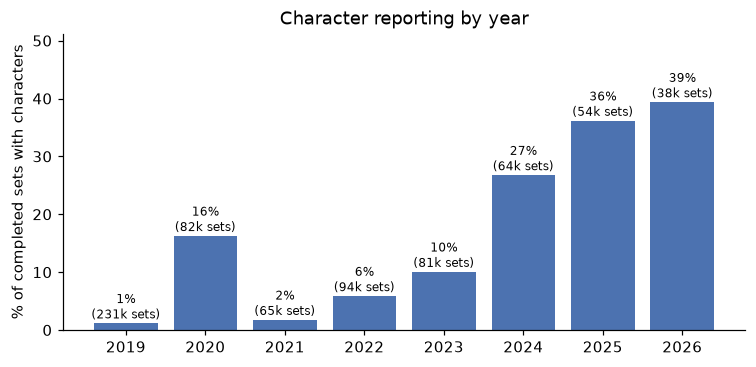

In [4]:
cov_year = clean.coverage(sets_all, "year")
save_table(cov_year, "coverage_by_year")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(cov_year.index.astype(str), cov_year.pct_with_chars, color="#4C72B0")
for x, (p, n) in enumerate(zip(cov_year.pct_with_chars, cov_year.sets)):
    ax.text(x, p + 0.8, f"{p:.0f}%\n({n/1000:.0f}k sets)", ha="center", fontsize=8)
ax.set_ylabel("% of completed sets with characters")
ax.set_title("Character reporting by year")
ax.set_ylim(0, cov_year.pct_with_chars.max() * 1.3)
save(fig, "coverage_by_year")
cov_year

,sets,events,pct_with_games,pct_with_chars
size_bucket,,,,
64-127,271470,1426,10.4,10.3
128-255,213861,723,14.5,14.3
256-511,91108,150,18.5,18.1
512-1023,70917,57,6.4,6.1
1024+,61828,20,5.8,5.8


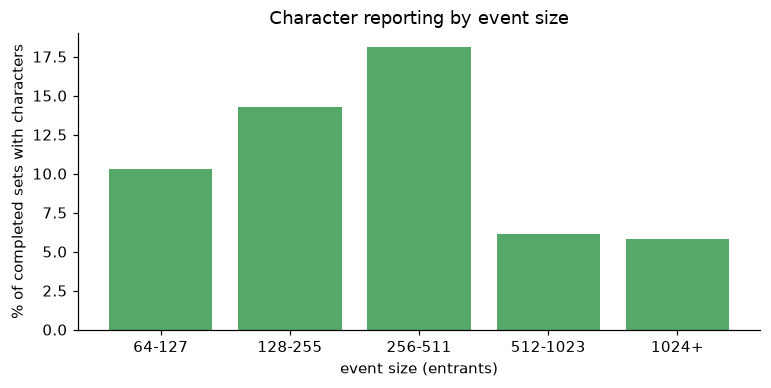

In [5]:
cov_size = clean.coverage(sets_all, "size_bucket")
save_table(cov_size, "coverage_by_event_size")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(cov_size.index.astype(str), cov_size.pct_with_chars, color="#55A868")
ax.set_xlabel("event size (entrants)")
ax.set_ylabel("% of completed sets with characters")
ax.set_title("Character reporting by event size")
save(fig, "coverage_by_event_size")
cov_size

pct_with_chars
0%         1465
1-25%       592
26-75%      142
76-100%     177


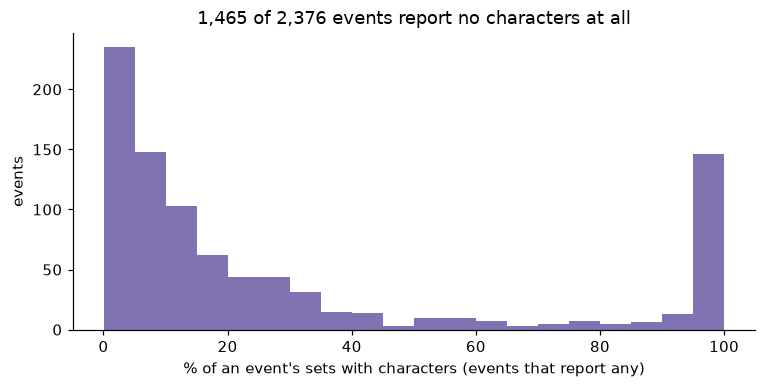

In [6]:
ev = clean.event_coverage(sets_all)
save_table(ev, "coverage_by_event")

bands = pd.cut(ev.pct_with_chars, [-0.1, 0, 25, 75, 100], labels=["0%", "1-25%", "26-75%", "76-100%"])
print(bands.value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(ev.pct_with_chars[ev.pct_with_chars > 0], bins=20, color="#8172B2")
ax.set_xlabel("% of an event's sets with characters (events that report any)")
ax.set_ylabel("events")
ax.set_title(f"{(ev.pct_with_chars == 0).sum():,} of {len(ev):,} events report no characters at all")
save(fig, "coverage_by_event")

In [7]:
# where the character data actually comes from
src_year = games.groupby("year").size().rename("games")
src_year = (src_year / src_year.sum() * 100).round(1).to_frame("% of clean games")
save_table(src_year, "games_by_year")
src_year.T

year,2019,2020,2021,2022,2023,2024,2025,2026
% of clean games,3.2,16.0,1.4,6.4,9.7,20.8,24.1,18.4


## 3. Sample sizes: are there enough games per matchup?

Mirrors excluded. Each matchup appears twice in the directed table (A vs B, B vs A are complements),
so counts below use one row per matchup. Wilson CIs treat games as independent; the bootstrap
resamples whole **sets**, since games in a set share the same two players.

In [8]:
m = clean.matchup_stats(pg, MIN_GAMES, bootstrap=N_BOOT)    # directed: char vs opp_char
mu = clean.undirected(m)                                     # one row per matchup
save_table(m, "matchups_directed")

thresholds = pd.DataFrame({
    "min games": [30, 50, 100, 200, 400],
    "matchups": [int((mu.games >= t).sum()) for t in (30, 50, 100, 200, 400)],
})
thresholds["% of observed"] = (thresholds.matchups / len(mu) * 100).round(1)
n_chars = pd.concat([games.p1_char, games.p2_char]).nunique()
print(f"{len(mu):,} matchups observed out of {n_chars * (n_chars - 1) // 2:,} possible; "
      f"median {mu.games.median():.0f} games per matchup")
thresholds

3,647 matchups observed out of 3,655 possible; median 51 games per matchup


,min games,matchups,% of observed
0,30,2591,71.0
1,50,1858,50.9
2,100,807,22.1
3,200,195,5.3
4,400,14,0.4


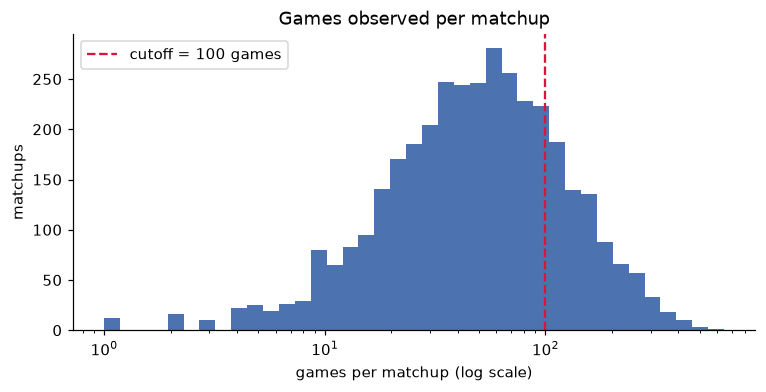

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(mu.games, bins=np.logspace(0, np.log10(mu.games.max()), 40), color="#4C72B0")
ax.set_xscale("log")
ax.axvline(MIN_GAMES, color="crimson", ls="--", label=f"cutoff = {MIN_GAMES} games")
ax.set_xlabel("games per matchup (log scale)")
ax.set_ylabel("matchups")
ax.set_title("Games observed per matchup")
ax.legend()
save(fig, "games_per_matchup")

bootstrap CIs are on average 1.20x as wide as Wilson


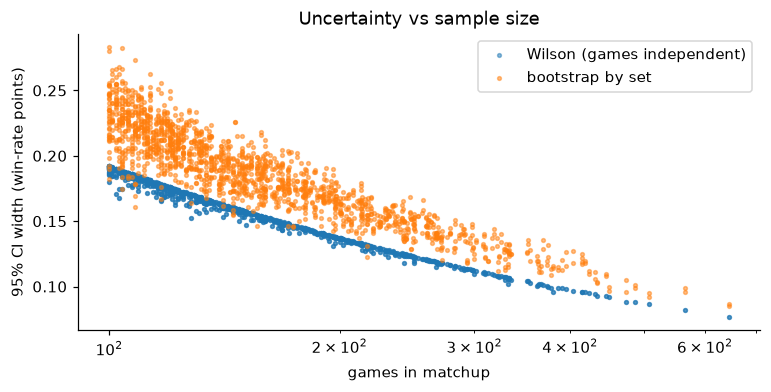

In [10]:
# how precise is a matchup estimate at a given sample size?
s = m[m.sufficient & m.boot_low.notna()]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(s.games, s.ci_high - s.ci_low, s=6, alpha=0.5, label="Wilson (games independent)")
ax.scatter(s.games, s.boot_high - s.boot_low, s=6, alpha=0.5, label="bootstrap by set")
ax.set_xscale("log")
ax.set_xlabel("games in matchup")
ax.set_ylabel("95% CI width (win-rate points)")
ax.set_title("Uncertainty vs sample size")
ax.legend()
save(fig, "ci_width_vs_games")
print(f"bootstrap CIs are on average {((s.boot_high - s.boot_low) / (s.ci_high - s.ci_low)).mean():.2f}x as wide as Wilson")

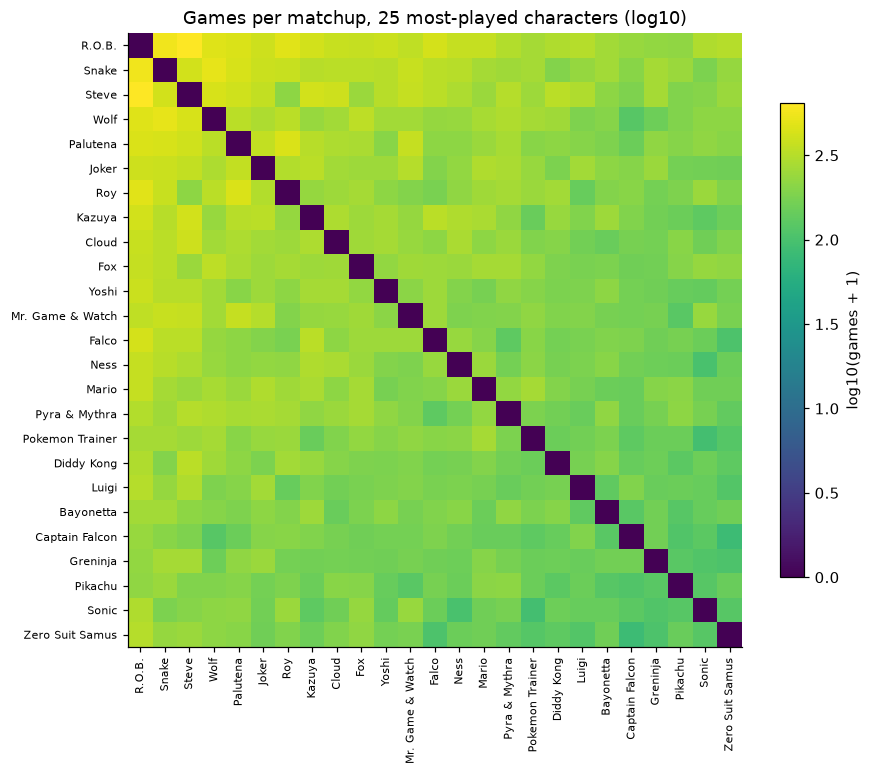

In [11]:
# matchup sample-size matrix for the most-played characters
top = clean.char_stats(pg).head(25).index
mat = m.reset_index().pivot(index="char", columns="opp_char", values="games").reindex(index=top, columns=top)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(np.log10(mat.fillna(0) + 1), cmap="viridis")
ax.set_xticks(range(len(top)), top, rotation=90, fontsize=7)
ax.set_yticks(range(len(top)), top, fontsize=7)
ax.set_title("Games per matchup, 25 most-played characters (log10)")
fig.colorbar(im, ax=ax, shrink=0.7, label="log10(games + 1)")
save(fig, "matchup_counts_heatmap")

## 4. Characters: usage and raw win rates

Raw win rates are **not** skill-adjusted: a character played mostly by top players will look strong.
They're a descriptive baseline, not a tier list.

,games_all,games,wins,players,usage_pct,win_rate,ci_low,ci_high
char,,,,,,,,
R.O.B.,17352,16854,9277,676,3.322,0.550,0.543,0.558
Snake,14869,14619,7878,507,2.846,0.539,0.531,0.547
Steve,14533,14063,7947,500,2.782,0.565,0.557,0.573
Wolf,13120,12858,6540,747,2.511,0.509,0.500,0.517
Palutena,12658,12436,6616,679,2.423,0.532,0.523,0.541
Joker,12260,12040,5722,893,2.347,0.475,0.466,0.484
Roy,12093,11781,5879,803,2.315,0.499,0.490,0.508
Kazuya,11841,11551,6321,478,2.267,0.547,0.538,0.556
Cloud,11743,11509,5441,930,2.248,0.473,0.464,0.482


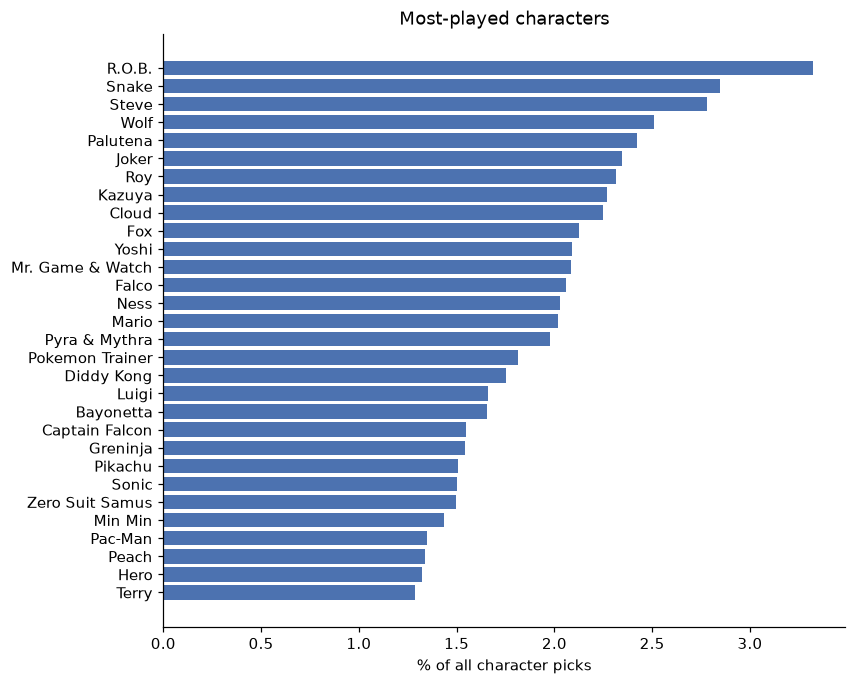

In [12]:
cs = clean.char_stats(pg)
save_table(cs, "characters")

fig, ax = plt.subplots(figsize=(8, 7))
t30 = cs.head(30).iloc[::-1]
ax.barh(t30.index, t30.usage_pct, color="#4C72B0")
ax.set_xlabel("% of all character picks")
ax.set_title("Most-played characters")
save(fig, "character_usage")
cs.head(10).round(3)

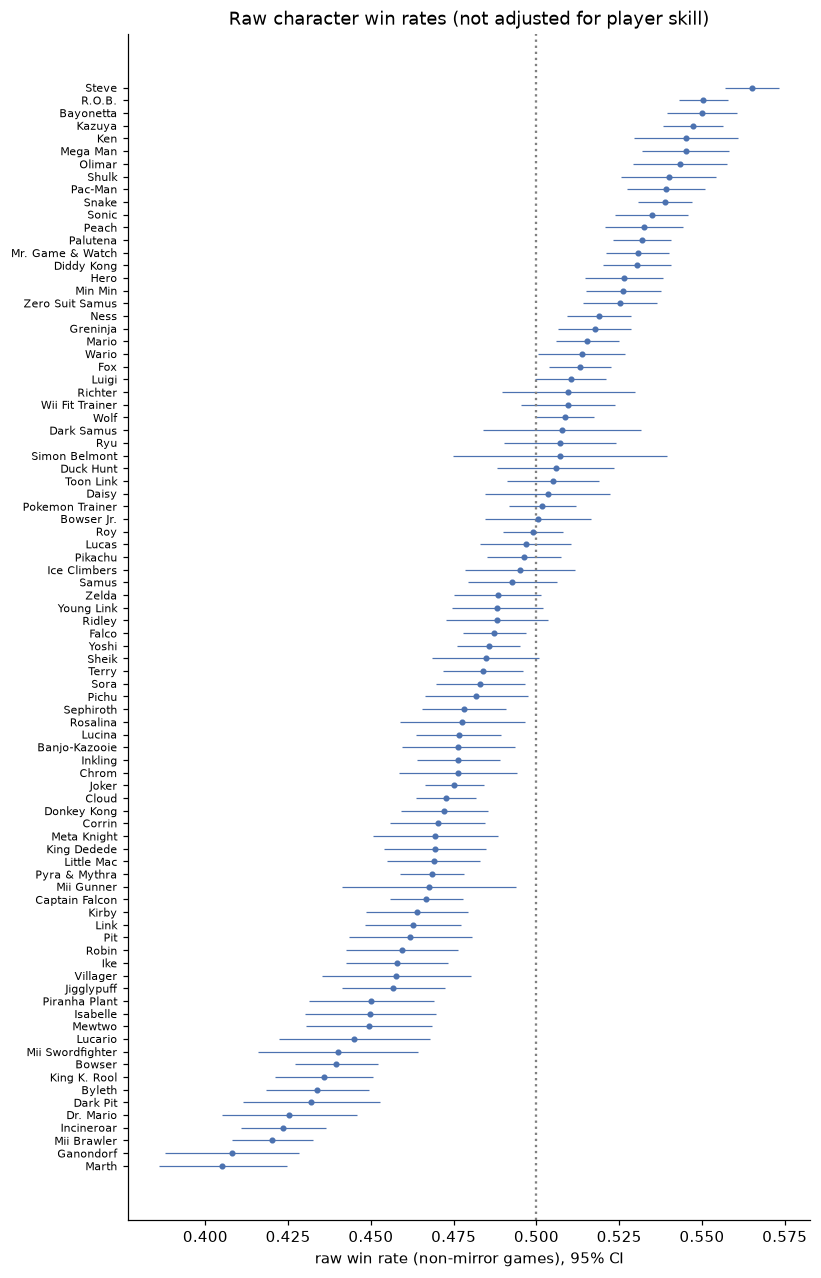

In [13]:
w = cs.sort_values("win_rate")
fig, ax = plt.subplots(figsize=(8, 14))
ax.errorbar(w.win_rate, range(len(w)), xerr=[w.win_rate - w.ci_low, w.ci_high - w.win_rate],
            fmt="o", ms=3, lw=0.8, color="#4C72B0")
ax.axvline(0.5, color="grey", ls=":")
ax.set_yticks(range(len(w)), w.index, fontsize=7)
ax.set_xlabel("raw win rate (non-mirror games), 95% CI")
ax.set_title("Raw character win rates (not adjusted for player skill)")
save(fig, "character_win_rates_raw")

## 5. Matchups with sufficient data

Which matchups depart from 50:50 by more than their uncertainty? Uses the set-level bootstrap CI.

In [14]:
suff = mu[mu.sufficient].copy()
suff["clear_winner"] = (suff.boot_low > 0.5) | (suff.boot_high < 0.5)
print(f"{len(suff):,} matchups with >= {MIN_GAMES} games; "
      f"{suff.clear_winner.sum():,} ({suff.clear_winner.mean():.0%}) have a CI that excludes 50%")
save_table(suff, "matchups_sufficient")

lopsided = suff.assign(edge=(suff.win_rate - 0.5).abs()).sort_values("edge", ascending=False)
lopsided.head(15)[["games", "sets", "players", "win_rate", "boot_low", "boot_high"]].round(3)

807 matchups with >= 100 games; 143 (18%) have a CI that excludes 50%


games  sets  players  win_rate  boot_low  boot_high
char          opp_char                                                            
Incineroar    Kazuya             103    44       37     0.262     0.165      0.356
King K. Rool  R.O.B.             128    52       35     0.273     0.176      0.366
Byleth        Steve              102    43       34     0.275     0.168      0.381
              Snake              103    40       37     0.301     0.196      0.402
Lucas         R.O.B.             131    54       36     0.305     0.203      0.405
Luigi         Mii Brawler        117    44       28     0.692     0.580      0.798
Fox           Inkling            104    41       34     0.692     0.583      0.810
Ike           Roy                122    46       42     0.311     0.212      0.410
Diddy Kong    Terry              130    47       32     0.685     0.595      0.774
Pac-Man       Pokemon Trainer    117    45       37     0.684     0.593      0.780
Bayonetta     Mario              151    56       41     0.682     0.593      0.772
Bowser        Terry              100    36       32     0.320     0.216      0.419
Incineroar    Palutena           109    49       40     0.321     0.226      0.419
Piranha Plant Steve              115    43       28     0.322     0.215      0.432
Mega Man      Ness               141    46       25     0.674     0.596      0.762

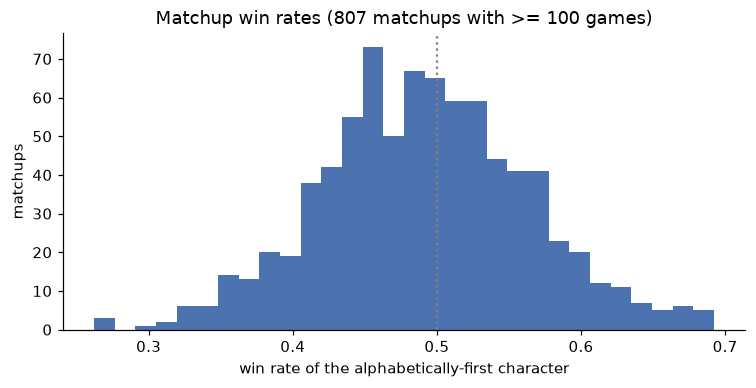

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(suff.win_rate, bins=30, color="#4C72B0")
ax.axvline(0.5, color="grey", ls=":")
ax.set_xlabel("win rate of the alphabetically-first character")
ax.set_ylabel("matchups")
ax.set_title(f"Matchup win rates ({len(suff):,} matchups with >= {MIN_GAMES} games)")
save(fig, "matchup_win_rate_distribution")

## 6. Player concentration: preview of the skill confound

If a few players account for most of a character's games, that character's win rate mostly measures
those players (the "Tweek effect"). This motivates the player-strength adjustment.

In [16]:
conc = clean.player_concentration(pg)
save_table(conc.to_frame("value"), "player_concentration")
conc

players                    18796.0
median_games_per_player       10.0
share_top_1pct                18.2
share_top_10pct               55.5
dtype: float64

In [17]:
# per character: share of its games played by its single most active player
per = pg.groupby(["char", "player_id"]).size().rename("g").reset_index()
dom = per.sort_values("g", ascending=False).groupby("char").agg(
    games=("g", "sum"), players=("player_id", "nunique"), top_player_games=("g", "first"))
dom["top_player_share_pct"] = (dom.top_player_games / dom.games * 100).round(1)
tags = pg.drop_duplicates("player_id").set_index("player_id").player_tag
top_id = per.sort_values("g", ascending=False).drop_duplicates("char").set_index("char").player_id
dom["top_player"] = top_id.map(tags)
dom = dom.sort_values("top_player_share_pct", ascending=False)
save_table(dom, "character_player_dominance")
dom.head(15)

,games,players,top_player_games,top_player_share_pct,top_player
char,,,,,
Kirby,4057,356,975,24.0,JeJaJeJa
Richter,2390,141,507,21.2,Squidplumber
Mega Man,5495,229,1076,19.6,Peabnut
Ridley,4092,279,777,19.0,smub
Peach,6993,263,1205,17.2,MuteAce
Banjo-Kazooie,3273,224,546,16.7,fair
Rosalina,2679,165,445,16.6,Dabuz
Simon Belmont,919,75,142,15.5,Aghi
Ken,3848,206,578,15.0,Jahzz0


## 7. Stages (sparse)

Stage is recorded for only a minority of games, so stage analysis is limited to that subset.

stage recorded in 16.9% of games


year,2019,2020,2021,2022,2023,2024,2025,2026
% games with stage,47.5,60.2,40.2,19.8,12.9,6.1,4.1,2.1


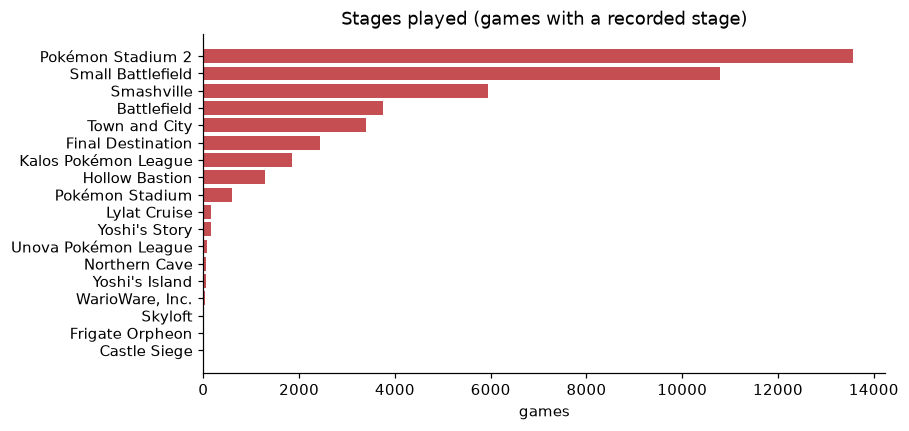

In [18]:
st = games.stage.value_counts()
print(f"stage recorded in {games.stage.notna().mean():.1%} of games")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(st.index[::-1], st.values[::-1], color="#C44E52")
ax.set_xlabel("games")
ax.set_title("Stages played (games with a recorded stage)")
save(fig, "stages")
save_table(st.to_frame("games"), "stages")
games.groupby("year").stage.apply(lambda s: round(s.notna().mean() * 100, 1)).to_frame("% games with stage").T

## 8. Outputs

Everything above is written to disk each run (when `SAVE = True`):

In [19]:
print("figures:", *sorted(p.name for p in FIG_DIR.glob("*.png")), sep="\n  ")
print("tables: ", *sorted(p.name for p in TAB_DIR.glob("*.csv")), sep="\n  ")

figures:
  character_usage.png
  character_win_rates_raw.png
  ci_width_vs_games.png
  coverage_by_event.png
  coverage_by_event_size.png
  coverage_by_year.png
  games_per_matchup.png
  matchup_counts_heatmap.png
  matchup_win_rate_distribution.png
  stages.png
tables: 
  character_player_dominance.csv
  characters.csv
  coverage_by_event.csv
  coverage_by_event_size.csv
  coverage_by_year.csv
  games_by_year.csv
  headline.csv
  matchups_directed.csv
  matchups_sufficient.csv
  player_concentration.csv
  stages.csv
